# Monsoon convection plots

Functions in `plotter.jl` (docstrings there: `?plot_time_height`). Edits to `plotter.jl` take effect without restarting, through Revise. On the cluster, write PNGs instead:
`julia --project=plots -e 'include("plotter.jl"); save_plots("run/ekamsat-ctl0")'`

In [ ]:
# plots/ is the folder with plotter.jl: look from where the kernel started, then at the usual checkouts (hpc, Mac)
candidates = (pwd(), joinpath(pwd(), "plots"), dirname(pwd()),
              "/ceoas/deszoeks/projects/monsoon-breeze/plots",
              expanduser("~/projects/monsoon-breeze/plots"))
plotsdir = candidates |> filter(d -> isfile(joinpath(d, "plotter.jl"))) |> first
cd(plotsdir)
using Pkg; Pkg.activate(plotsdir)
using Revise
includet(joinpath(plotsdir, "plotter.jl"))

rundir = joinpath(dirname(plotsdir), "run", "ekamsat-ctl0")

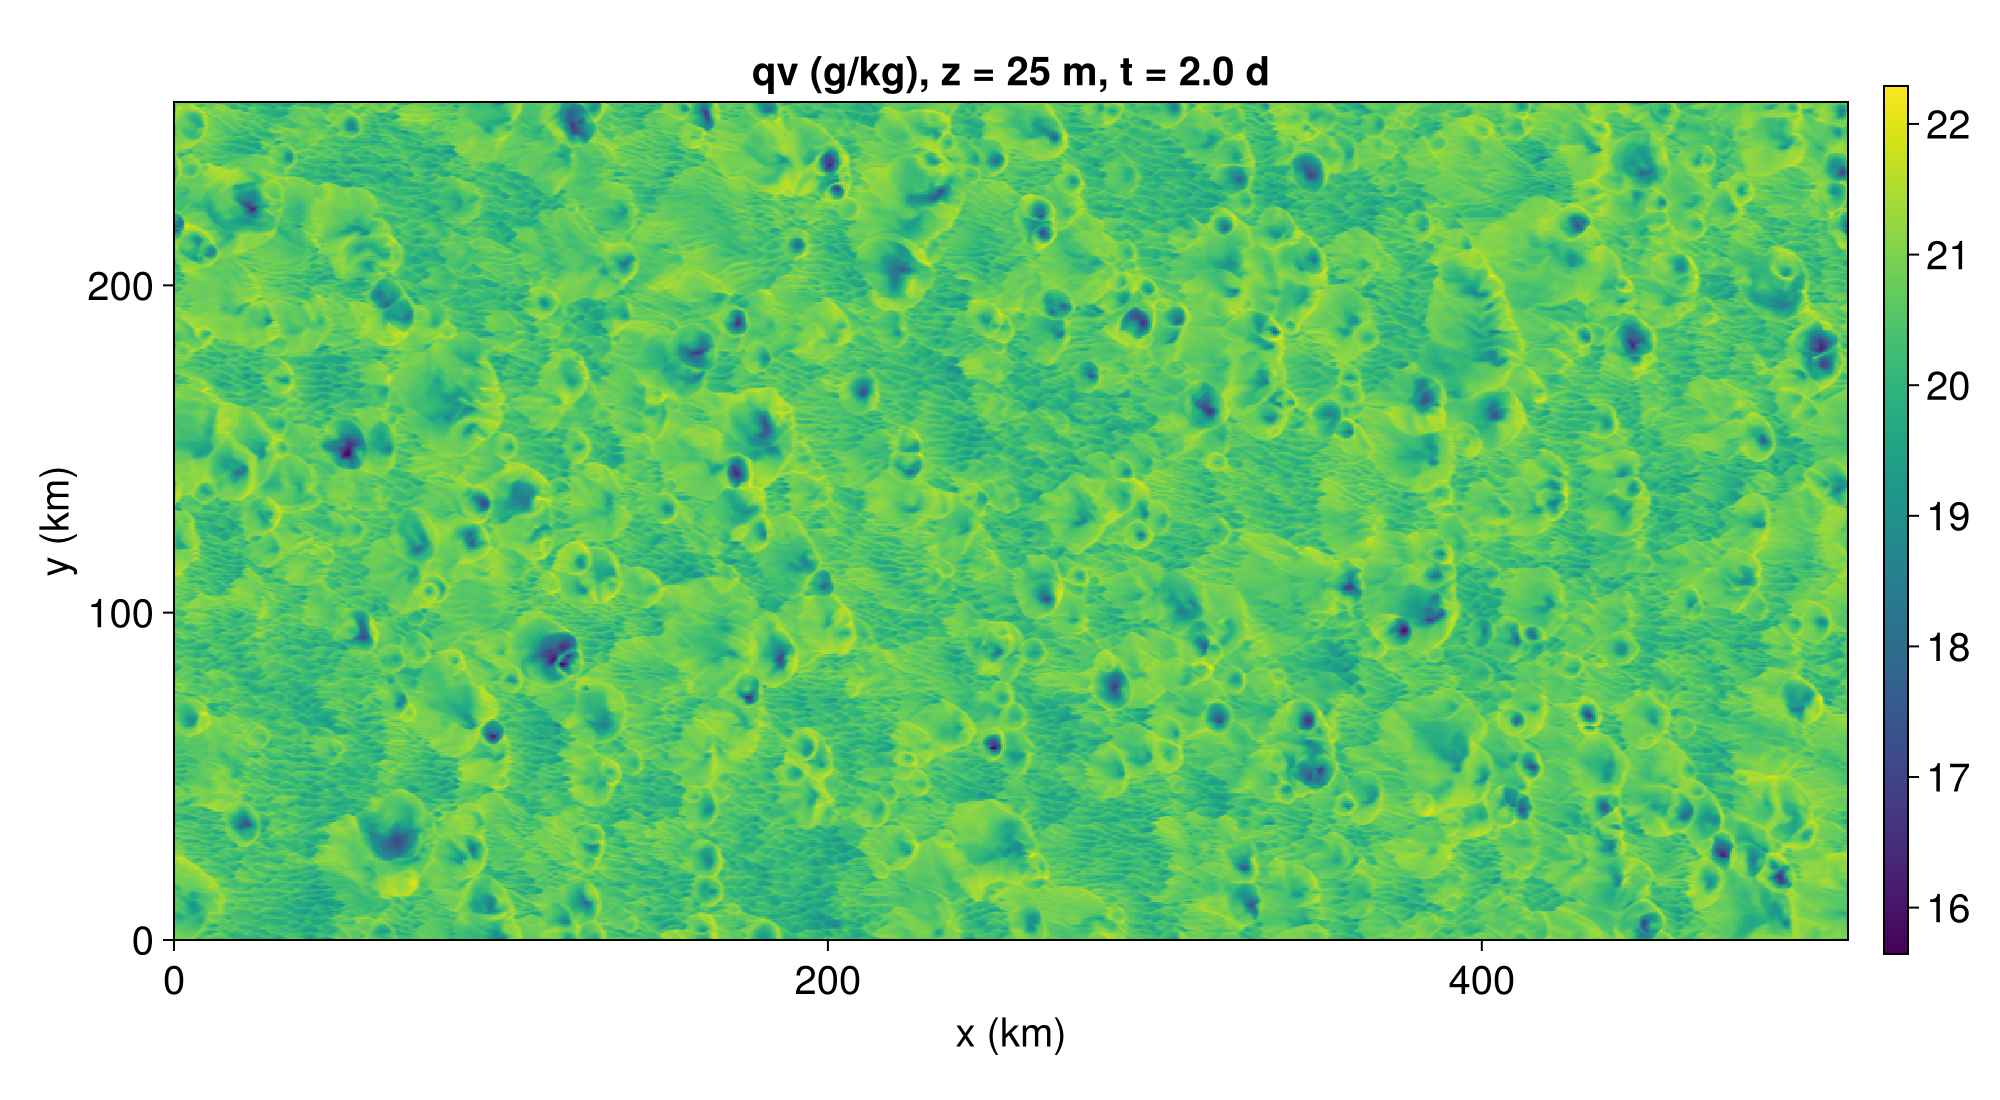

In [6]:
plot_xy(rundir, "qv"; n = last)            # lowest level, hourly (_surface.nc)

In [7]:
snapshot_times(rundir)                     # days of the 3D snapshots (_fields.nc)

3-element Vector{Float64}:
 0.0
 1.0
 2.0

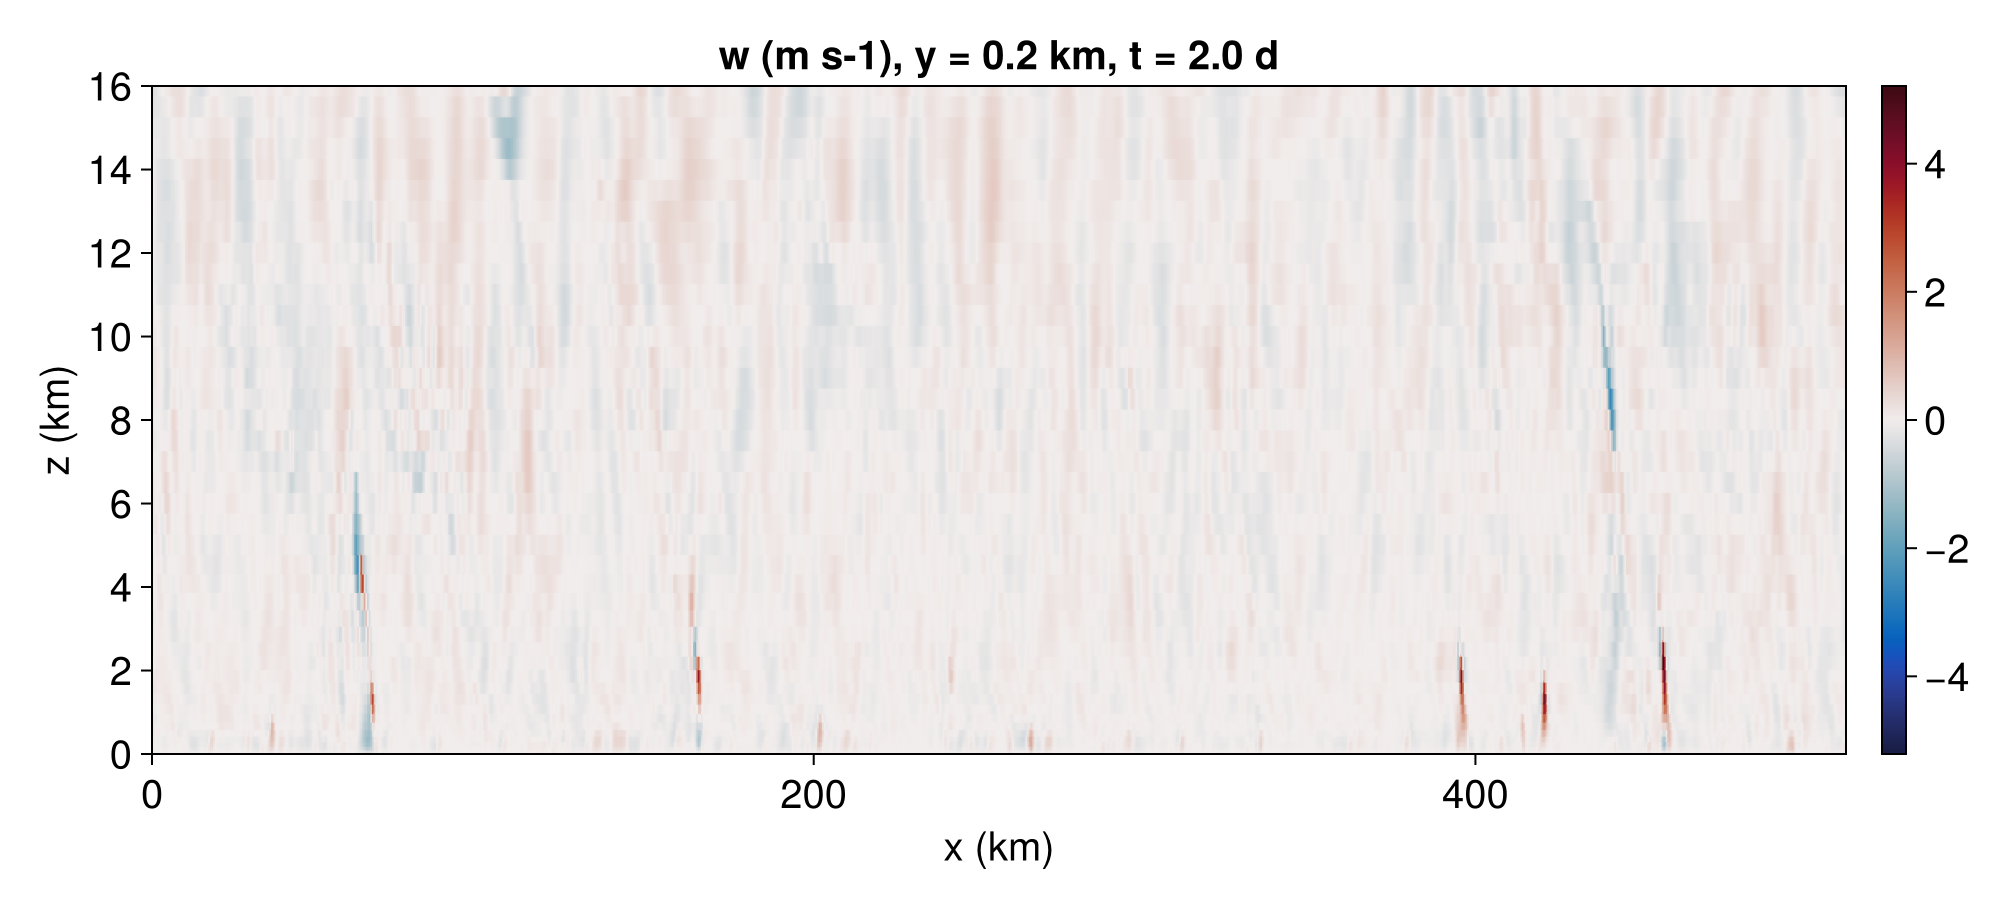

In [8]:
fig_xz = plot_xz(rundir, "w"; j = 1, n = last)

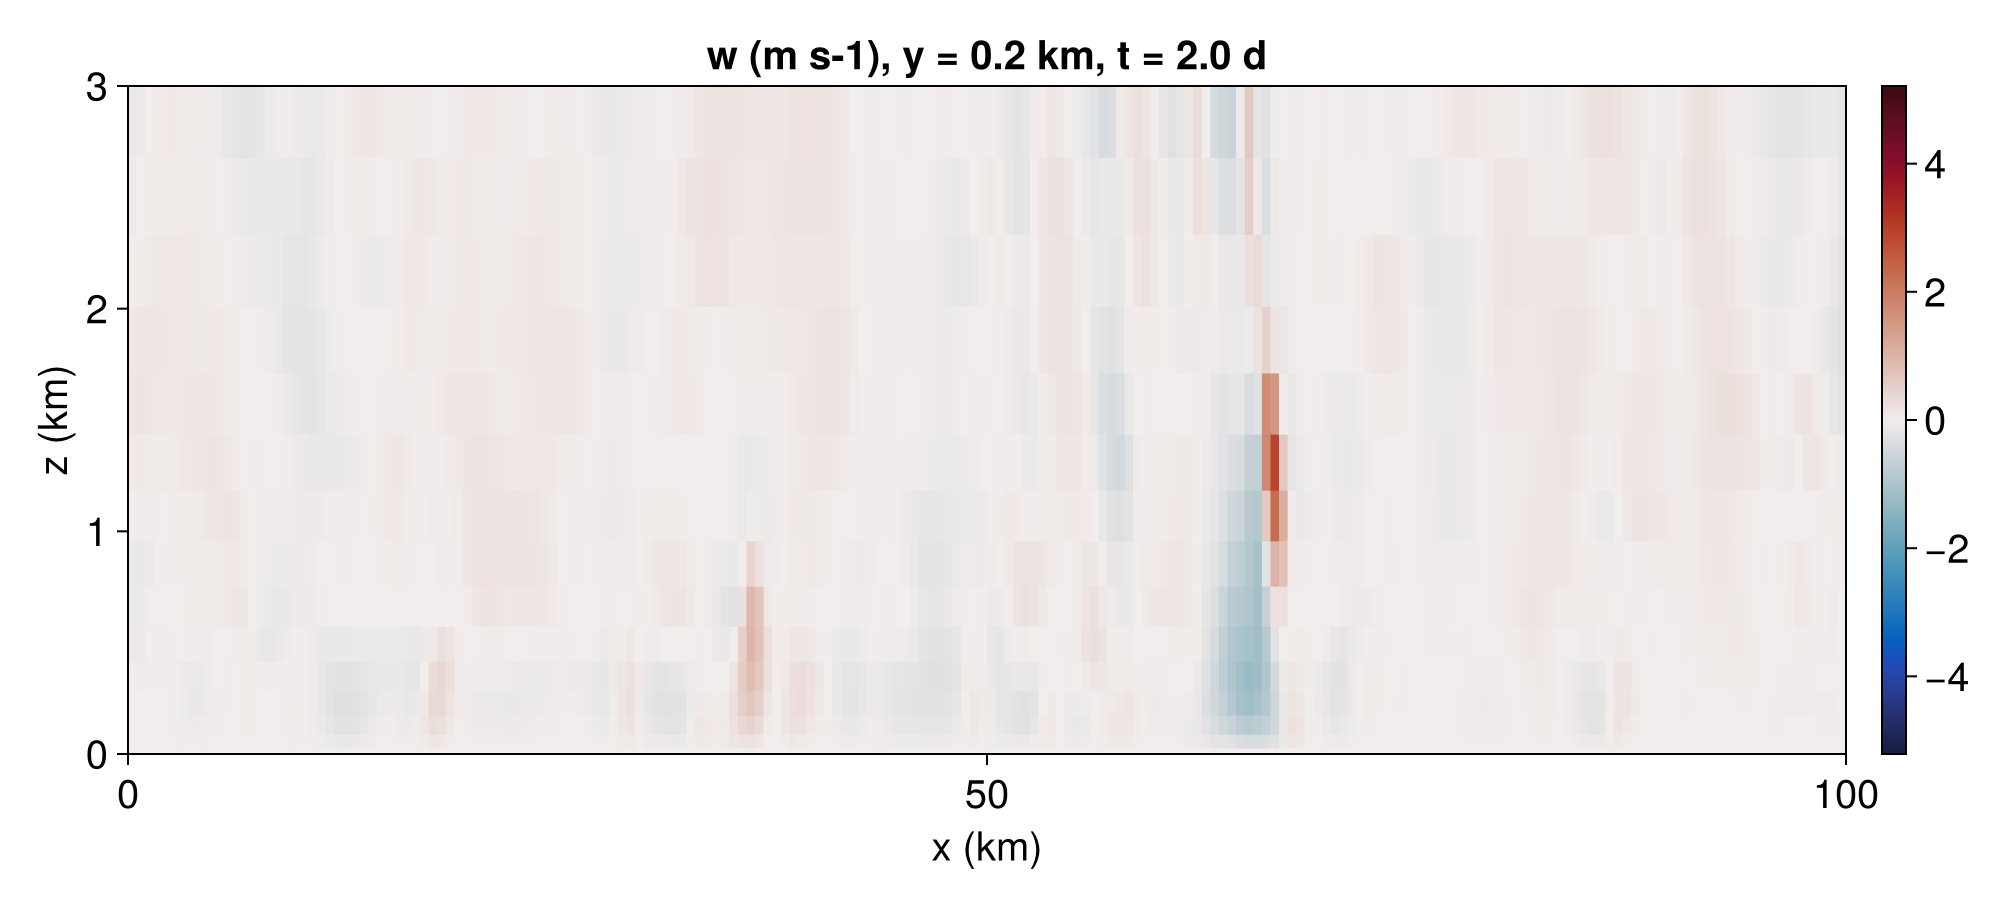

In [9]:
# Zoom the x–z section to the lowest 3 km and the first 100 km
ax = plot_axes(fig_xz)[1]
limits!(ax, 0, 100, 0, 3)     # x (km), z (km)
fig_xz

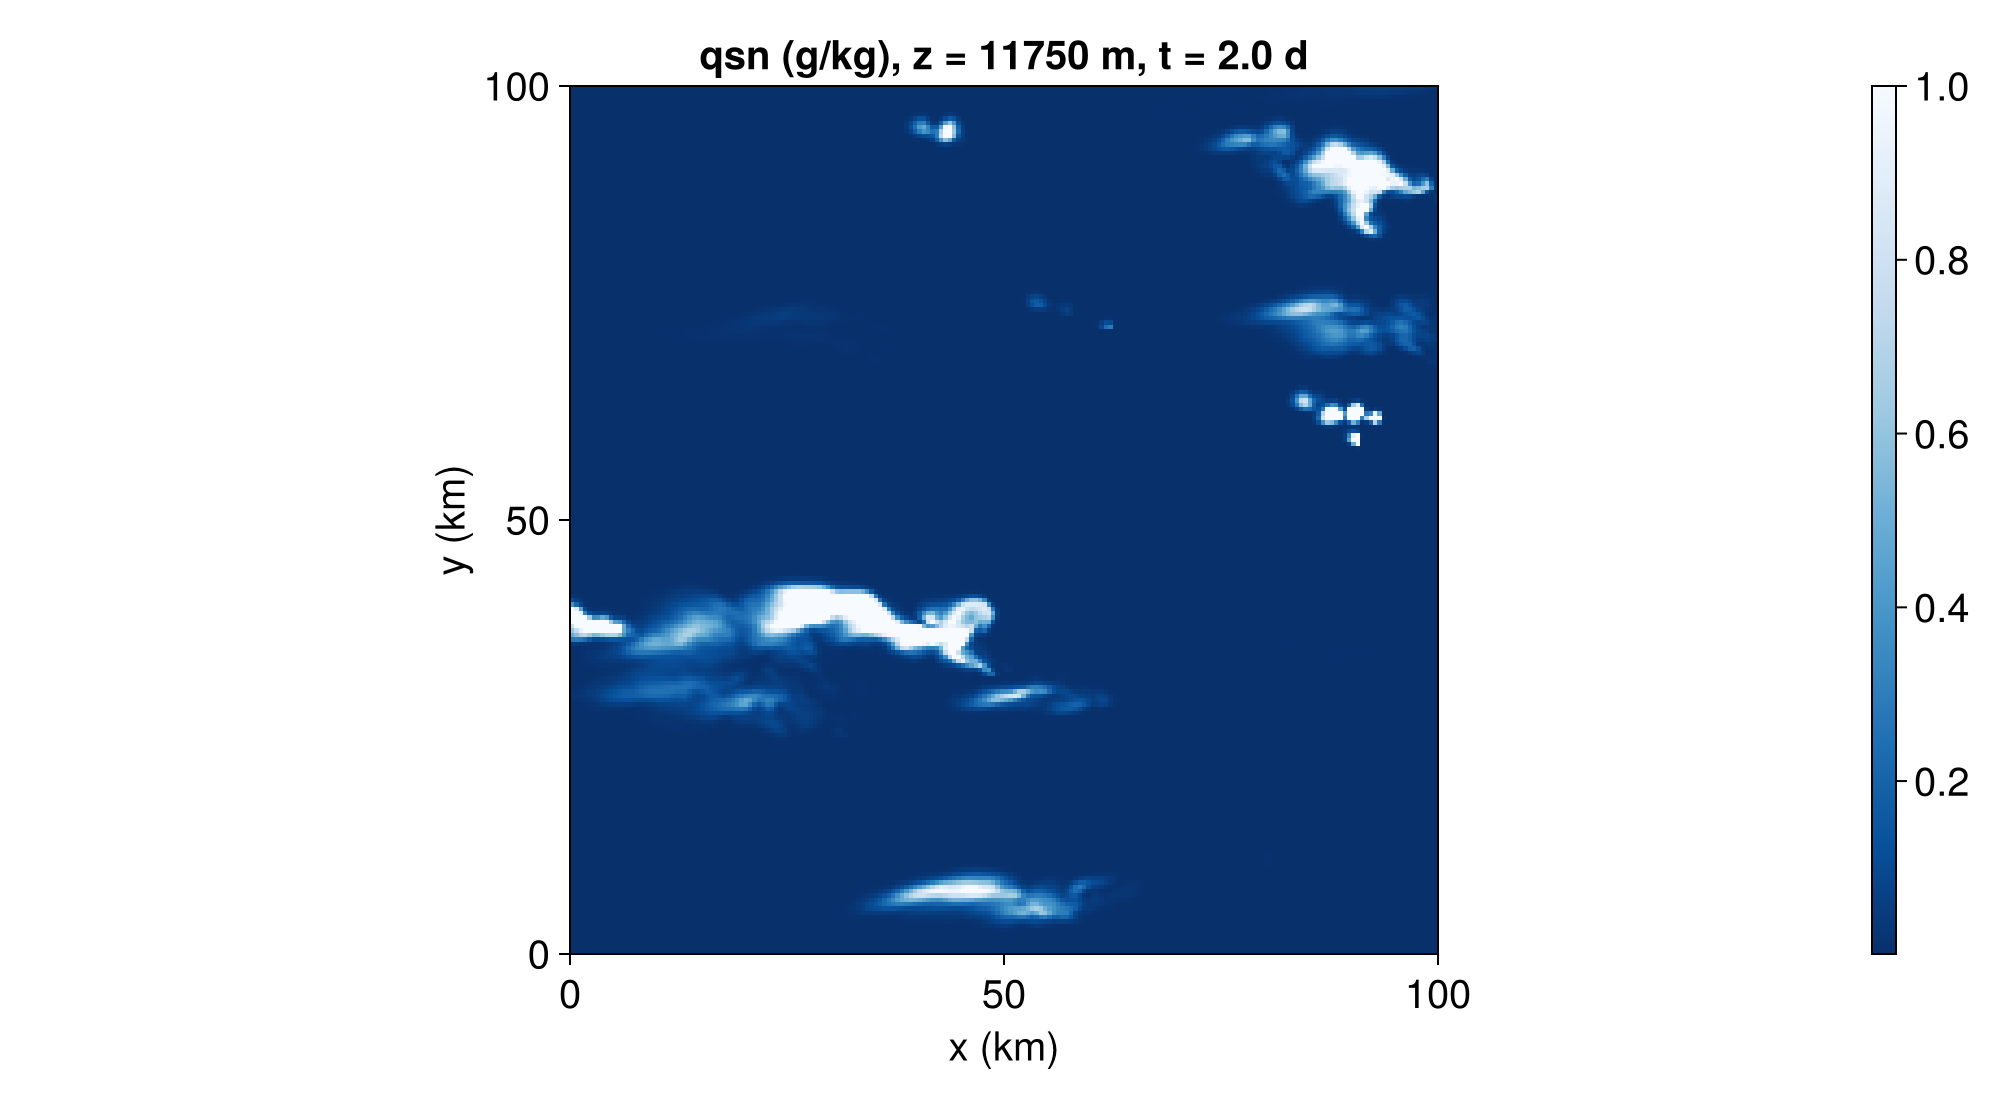

In [37]:
# log_10(x) = log10(max(x,1e-5))
fig_qcl = plot_xy(read_snapshot(rundir, "qci"; n = last); z = 12_000)   # a level of a 3D snapshot
fig_qcl = plot_xy(read_snapshot(rundir, "qsn"; n = last); z = 12_000)   # a level of a 3D snapshot
ax = plot_axes(fig_qcl)[1]
limits!(ax, 0, 100, 0, 100)
hm = ax.scene.plots[1]     # the heatmap in the first axis
hm.colorrange = (1e-3, 1)    # in the plotted units (log 10 g/kg here)
hm.colormap = Reverse(:Blues)
# hm.colorscale = log10
fig_qcl

In [11]:
# The latest state, from the newest checkpoint
ck = read_checkpoint(rundir)
keys(ck.fields)

(:ρu, :ρv, :ρw, :ρθ, :ρqᵛ, :ρqᶜˡ, :ρqᶜⁱ, :ρqʳ, :ρqˢⁿ, :ρe)

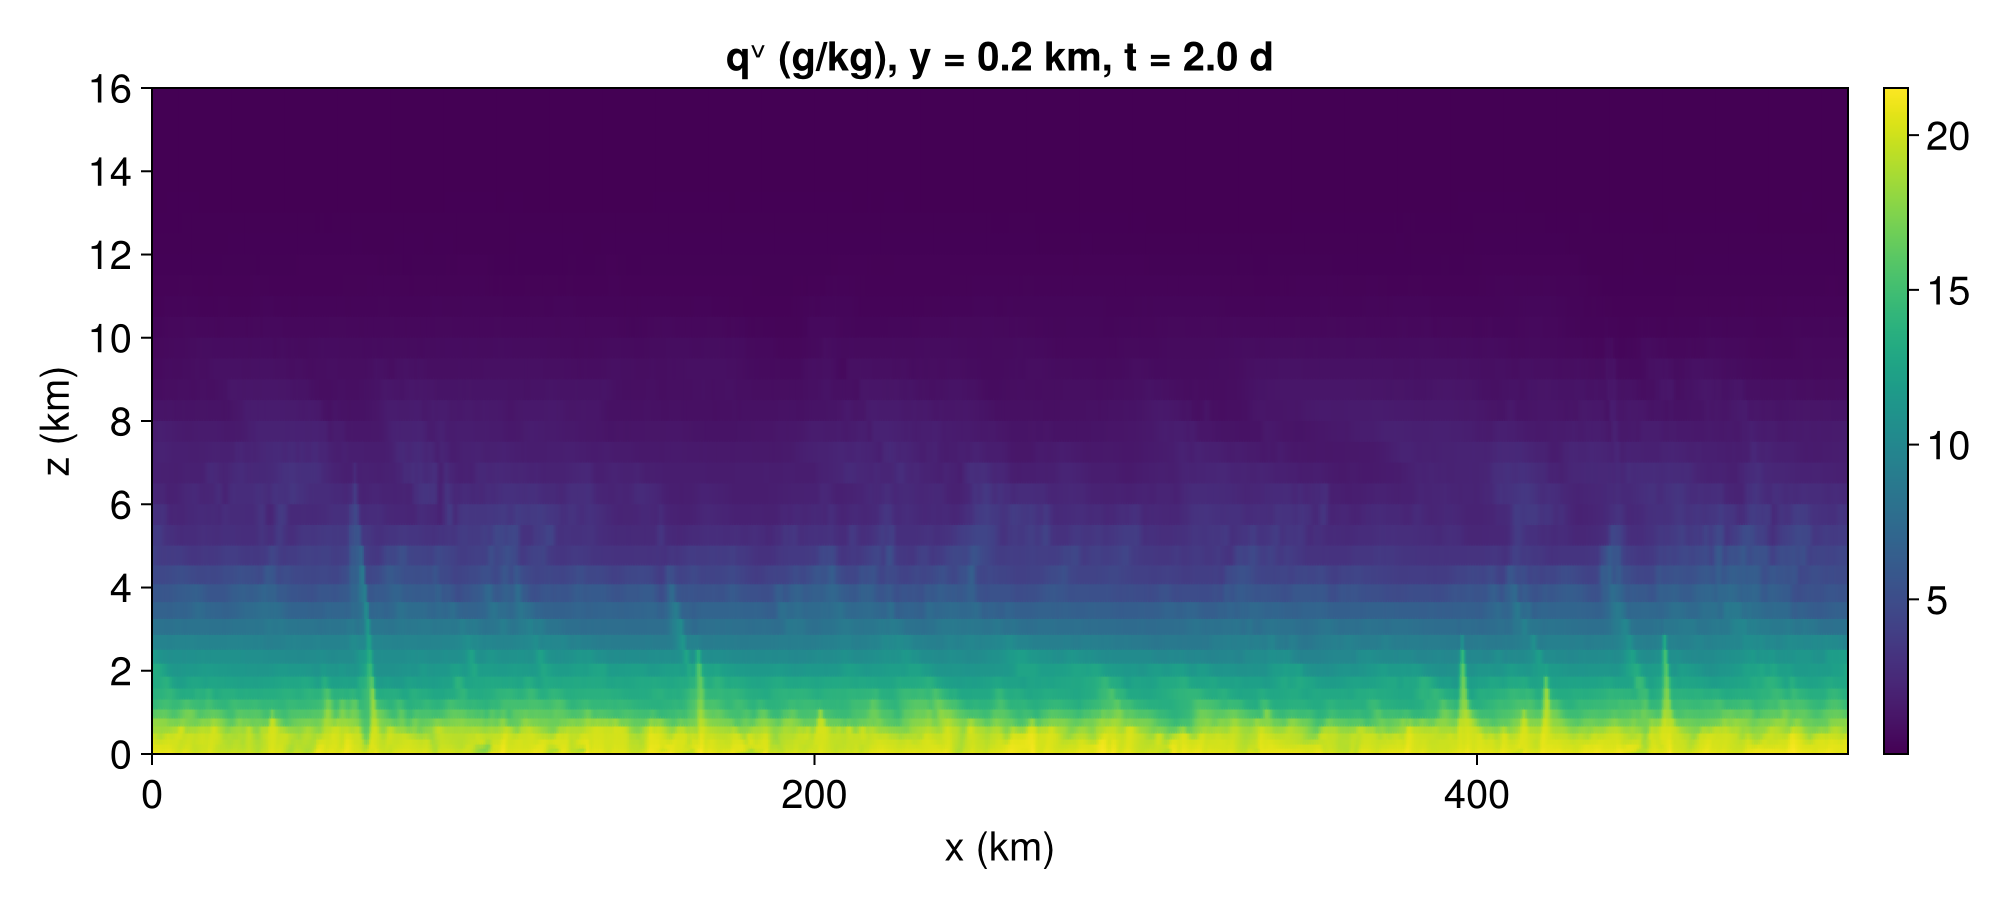

In [12]:
plot_xz(checkpoint_snapshot(ck, :ρqᵛ); j = 1)

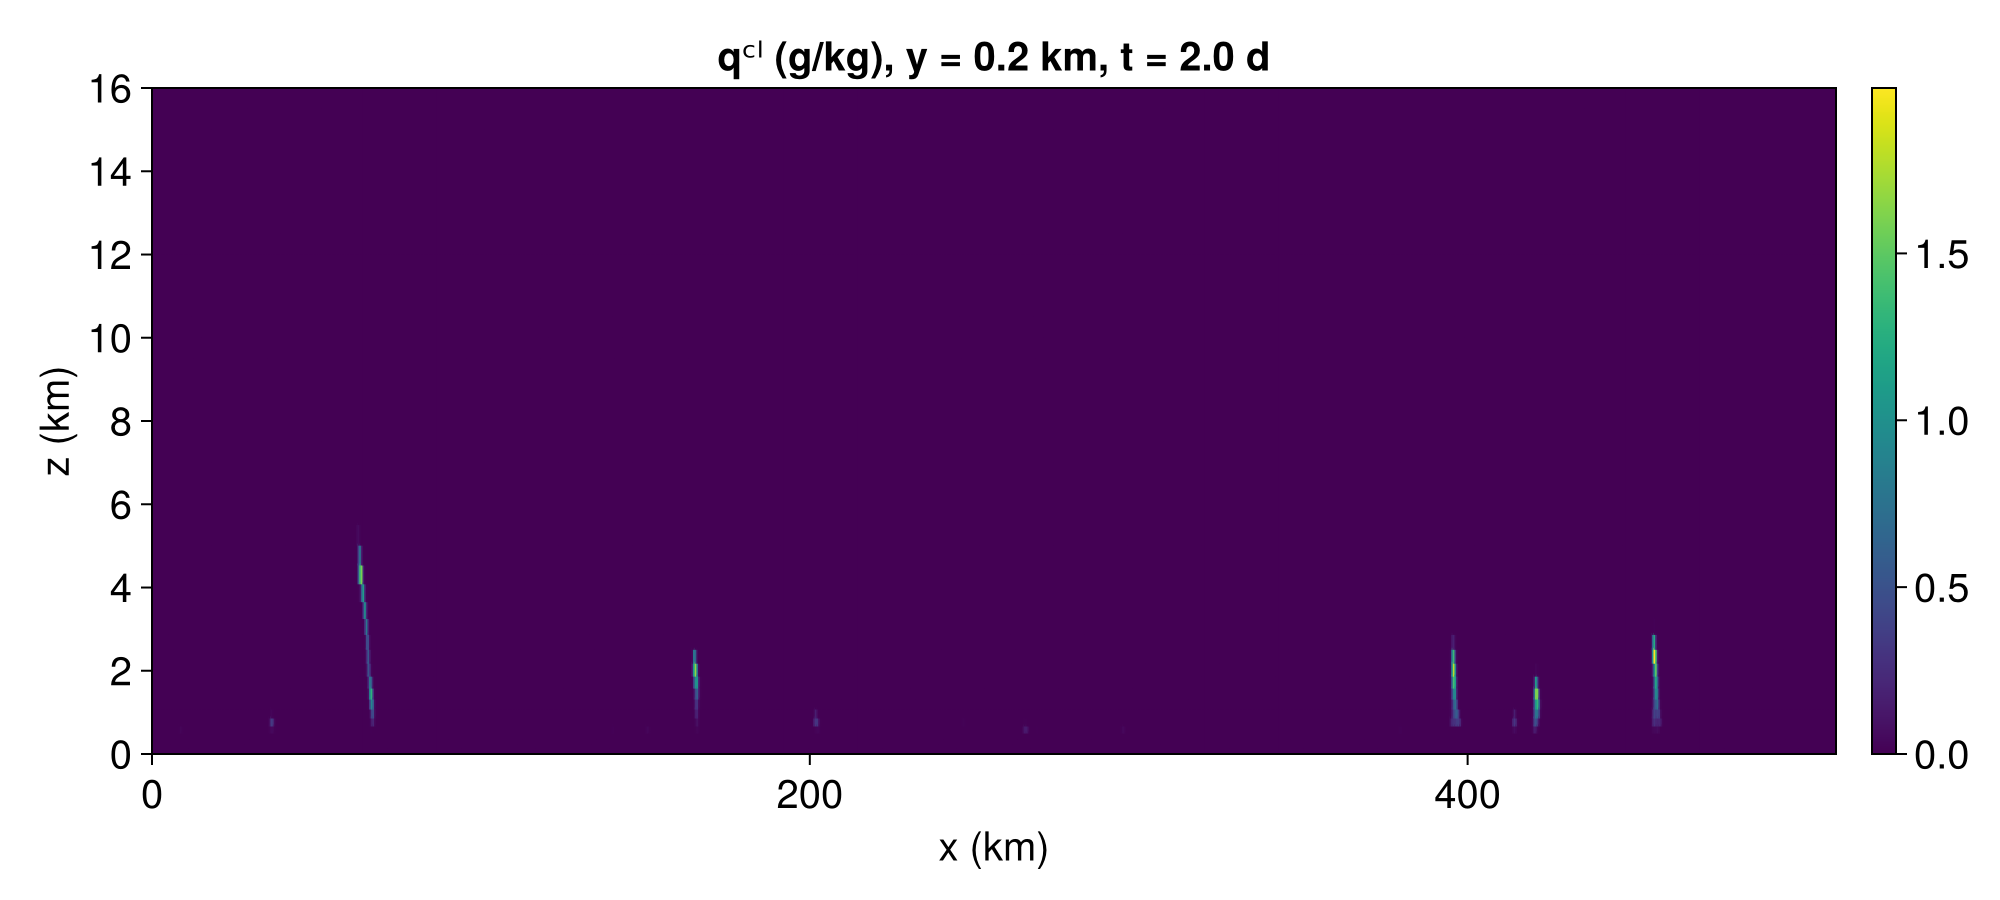

In [13]:
plot_xz(checkpoint_snapshot(ck, :ρqᶜˡ); j = 1)
